In [1]:
import trimesh
from IPython.display import Image, display

from hac.constants import MODEL_BASE_RADII
from hac.mesh import normalize_mesh_to_challenge_cylinder
from hac.convex_inversion_multi import ConvexInversionMulti, _facet_normals_and_areas

%load_ext autoreload
%autoreload 2

## Convex inversion pipeline

In [ ]:
# Asteroid 2 is the smallest/most convex public model, with a known
# near-convex ground truth
ASTEROID = 2
CYLINDER_R = MODEL_BASE_RADII[ASTEROID]
#This simplifed mesh is simply the convex hull of the ground truth ast2 (same shape just less facets)
GROUND_TRUTH_STL = "workspaces/christian/stls/asteroid2_simplified.stl"

gt_mesh = normalize_mesh_to_challenge_cylinder(
    trimesh.load(GROUND_TRUTH_STL, force="mesh"), target_R=CYLINDER_R
)
GT_NORMALS, GT_AREAS = _facet_normals_and_areas(gt_mesh)

In [3]:
# Set up inversion class and load data
CI = ConvexInversionMulti(cylinder_radius=CYLINDER_R, max_faces=1500)
CI.load_lightcurve_data(model_num=ASTEROID, origin="real", curve_type="binary")

Using 1280 faces
Observations (real/binary): 28 cameras x 842 phases = 23576 data points


Optionally fit the forward model parameters from some shape

In [ ]:
# Fit the scattering-law parameter against the known ground-truth shape
PER_CAM_GROUP_FN = lambda cam: cam # use this grouping to fit different parameters for each angle
CI.fit_scattering_params(normals=GT_NORMALS, areas=GT_AREAS,group_fn=PER_CAM_GROUP_FN);

   0_bottom ( 1 cams): best mu0_threshold = 0.020  (mse=0.003044)
     0_hor1 ( 1 cams): best mu0_threshold = 0.020  (mse=0.006104)
     0_hor2 ( 1 cams): best mu0_threshold = 0.020  (mse=0.003293)
      0_top ( 1 cams): best mu0_threshold = 0.020  (mse=0.006268)
  45_bottom ( 1 cams): best mu0_threshold = 0.240  (mse=0.004489)
    45_hor1 ( 1 cams): best mu0_threshold = 0.240  (mse=0.004356)
    45_hor2 ( 1 cams): best mu0_threshold = 0.240  (mse=0.003978)
     45_top ( 1 cams): best mu0_threshold = 0.240  (mse=0.004333)
  90_bottom ( 1 cams): best mu0_threshold = 0.040  (mse=0.029858)
    90_hor1 ( 1 cams): best mu0_threshold = 0.020  (mse=0.045105)
    90_hor2 ( 1 cams): best mu0_threshold = 0.020  (mse=0.042500)
     90_top ( 1 cams): best mu0_threshold = 0.020  (mse=0.025581)
  135_bottom ( 1 cams): best mu0_threshold = 0.040  (mse=0.058620)
   135_hor1 ( 1 cams): best mu0_threshold = 0.020  (mse=0.129656)
   135_hor2 ( 1 cams): best mu0_threshold = 0.040  (mse=0.060211)
    135_t

Build forward matrix

In [5]:
CI.build_forward()

Forward matrix A (real/binary): (23576, 1280)  (241.4 MB)


Fit areas to the data

Faster to run a GPU (with `avoid_gpu` = False) if one is available

In [8]:
CI.fit_areas(convexity_regularization=0.1, optimizer="cg", max_iter=10000, avoid_gpu=False)

Running CG  (n_params=1280, parametrization='log')...
  iter 1000: cost = 2340.915751
  iter 2000: cost = 2339.654376
  iter 3000: cost = 2339.343021
  iter 4000: cost = 2338.814330
  iter 5000: cost = 2338.507301
  iter 6000: cost = 2338.303417
  iter 7000: cost = 2338.276419
  iter 8000: cost = 2338.176932
  iter 9000: cost = 2338.123184
  iter 10000: cost = 2338.036625

Maximum number of iterations has been exceeded.
Cost: 2338.036625


Add dark area and optionally remove small areas

In [9]:
CI.refine_areas()

Added dark area. Dark area percentage: 0.000944%.
If this is large (>1%), recompute the areas with larger convexity regularization.


Showcase lightcurve fit

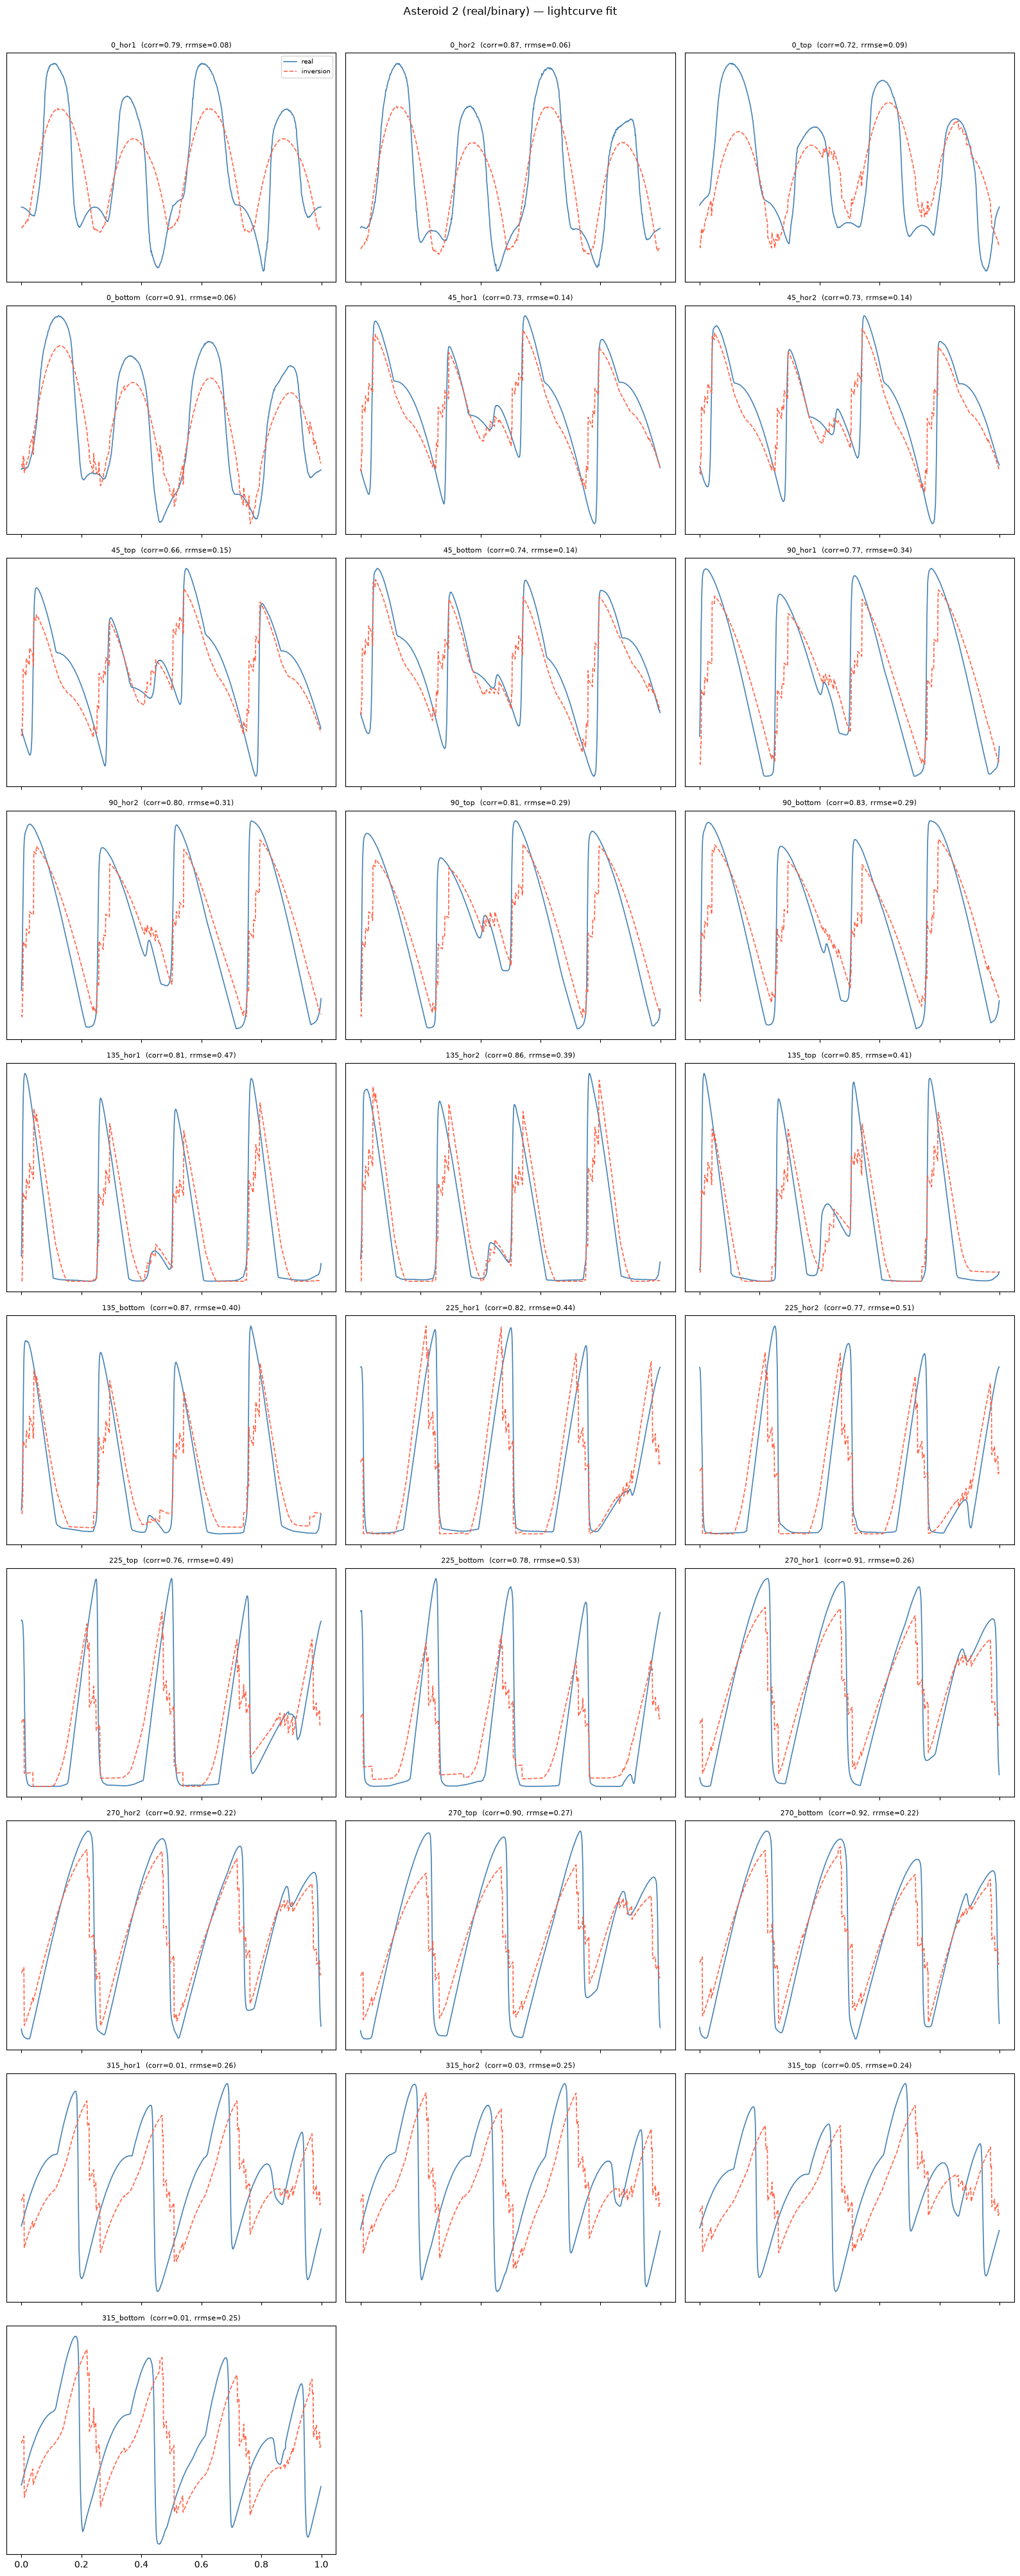

Overall MSE (normalised): 0.198340
Overall RRMSE:            0.274867
Overall correlation:      0.700223


In [10]:
CI.lightcurve_fit(show=True);

Minkowski reconstruction to reconstruct a mesh from the facets

Currently only implemented on CPU

In [11]:
CI.minkowski_reconstruction();

  iter    50: volume=226200.991400 alphak=0.533690
  iter   100: volume=241235.876090 alphak=0.250281
  iter   150: volume=250627.466949 alphak=0.261615
  iter   200: volume=257277.578203 alphak=0.340197
  iter   250: volume=262506.215318 alphak=0.294621
  iter   300: volume=266775.472192 alphak=0.279818
  iter   350: volume=270454.618134 alphak=0.195507
  iter   400: volume=273630.911508 alphak=0.189299
  iter   450: volume=276484.065119 alphak=0.182795
  iter   500: volume=279067.446848 alphak=0.179114
  iter   550: volume=281429.701876 alphak=0.173784
  iter   600: volume=283603.052440 alphak=0.167338
  iter   650: volume=285612.608356 alphak=0.159186
  iter   700: volume=287477.225719 alphak=0.149759
  iter   750: volume=289212.990442 alphak=0.138759
  iter   800: volume=290833.809905 alphak=0.125303
  iter   850: volume=292352.901688 alphak=0.106656
  iter   900: volume=293757.272265 alphak=0.134962
  iter   950: volume=295120.869655 alphak=0.096449
  iter  1000: volume=296381.929

Evaluate and save result

Voxel similarity vs. ground truth (surface-shell): 0.0621
Voxel similarity vs. ground truth (solid-fill):      0.8890
Lightcurve vs. ground-truth mesh (phase shift=836 samples):
  mean correlation: 0.8642
  mean RRMSE:       0.2278
Saved reconstruction STL to reconstructions/asteroid2_real_binary.stl
Saved multi-angle view plot to reconstructions/asteroid2_real_binary_views.png
Saved lightcurve comparison plot to reconstructions/asteroid2_real_binary_lightcurves_vs_truth.png


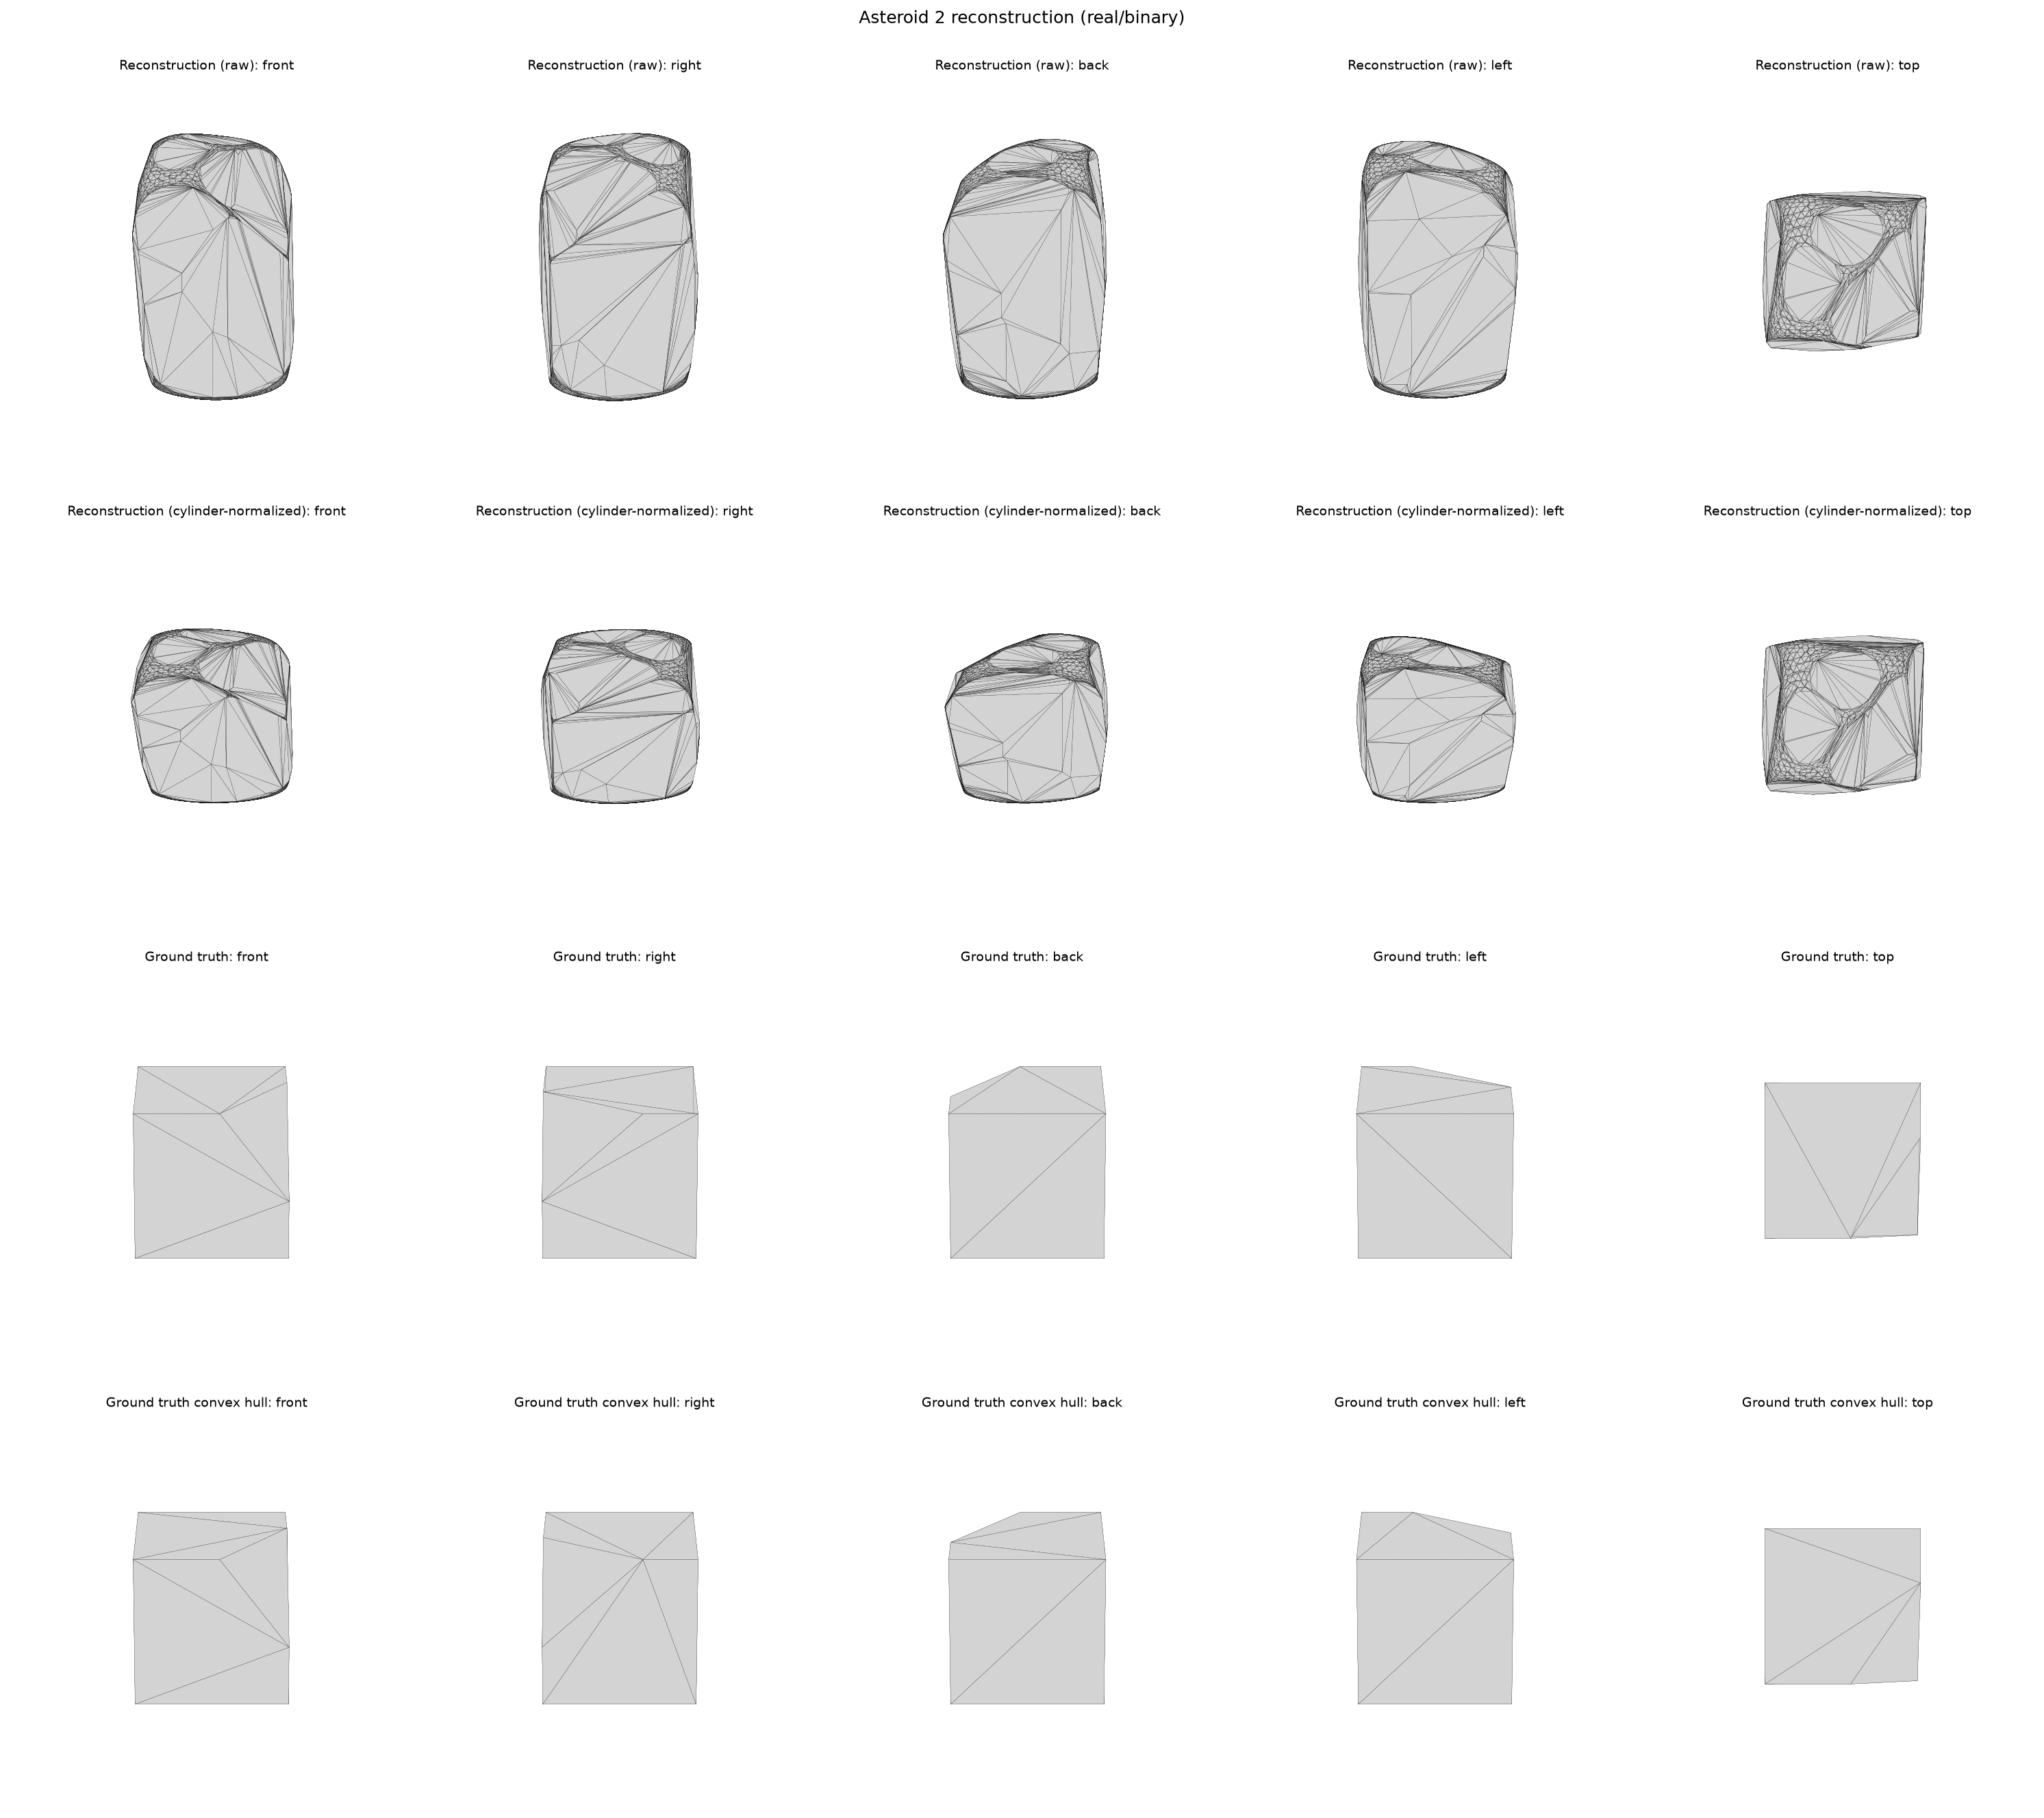

In [12]:
CI.evaluate_against_ground_truth(ground_truth_stl_path=GROUND_TRUTH_STL)
paths = CI.save_reconstruction(out_dir="reconstructions")
display(Image(filename=str(paths["views_png"])))

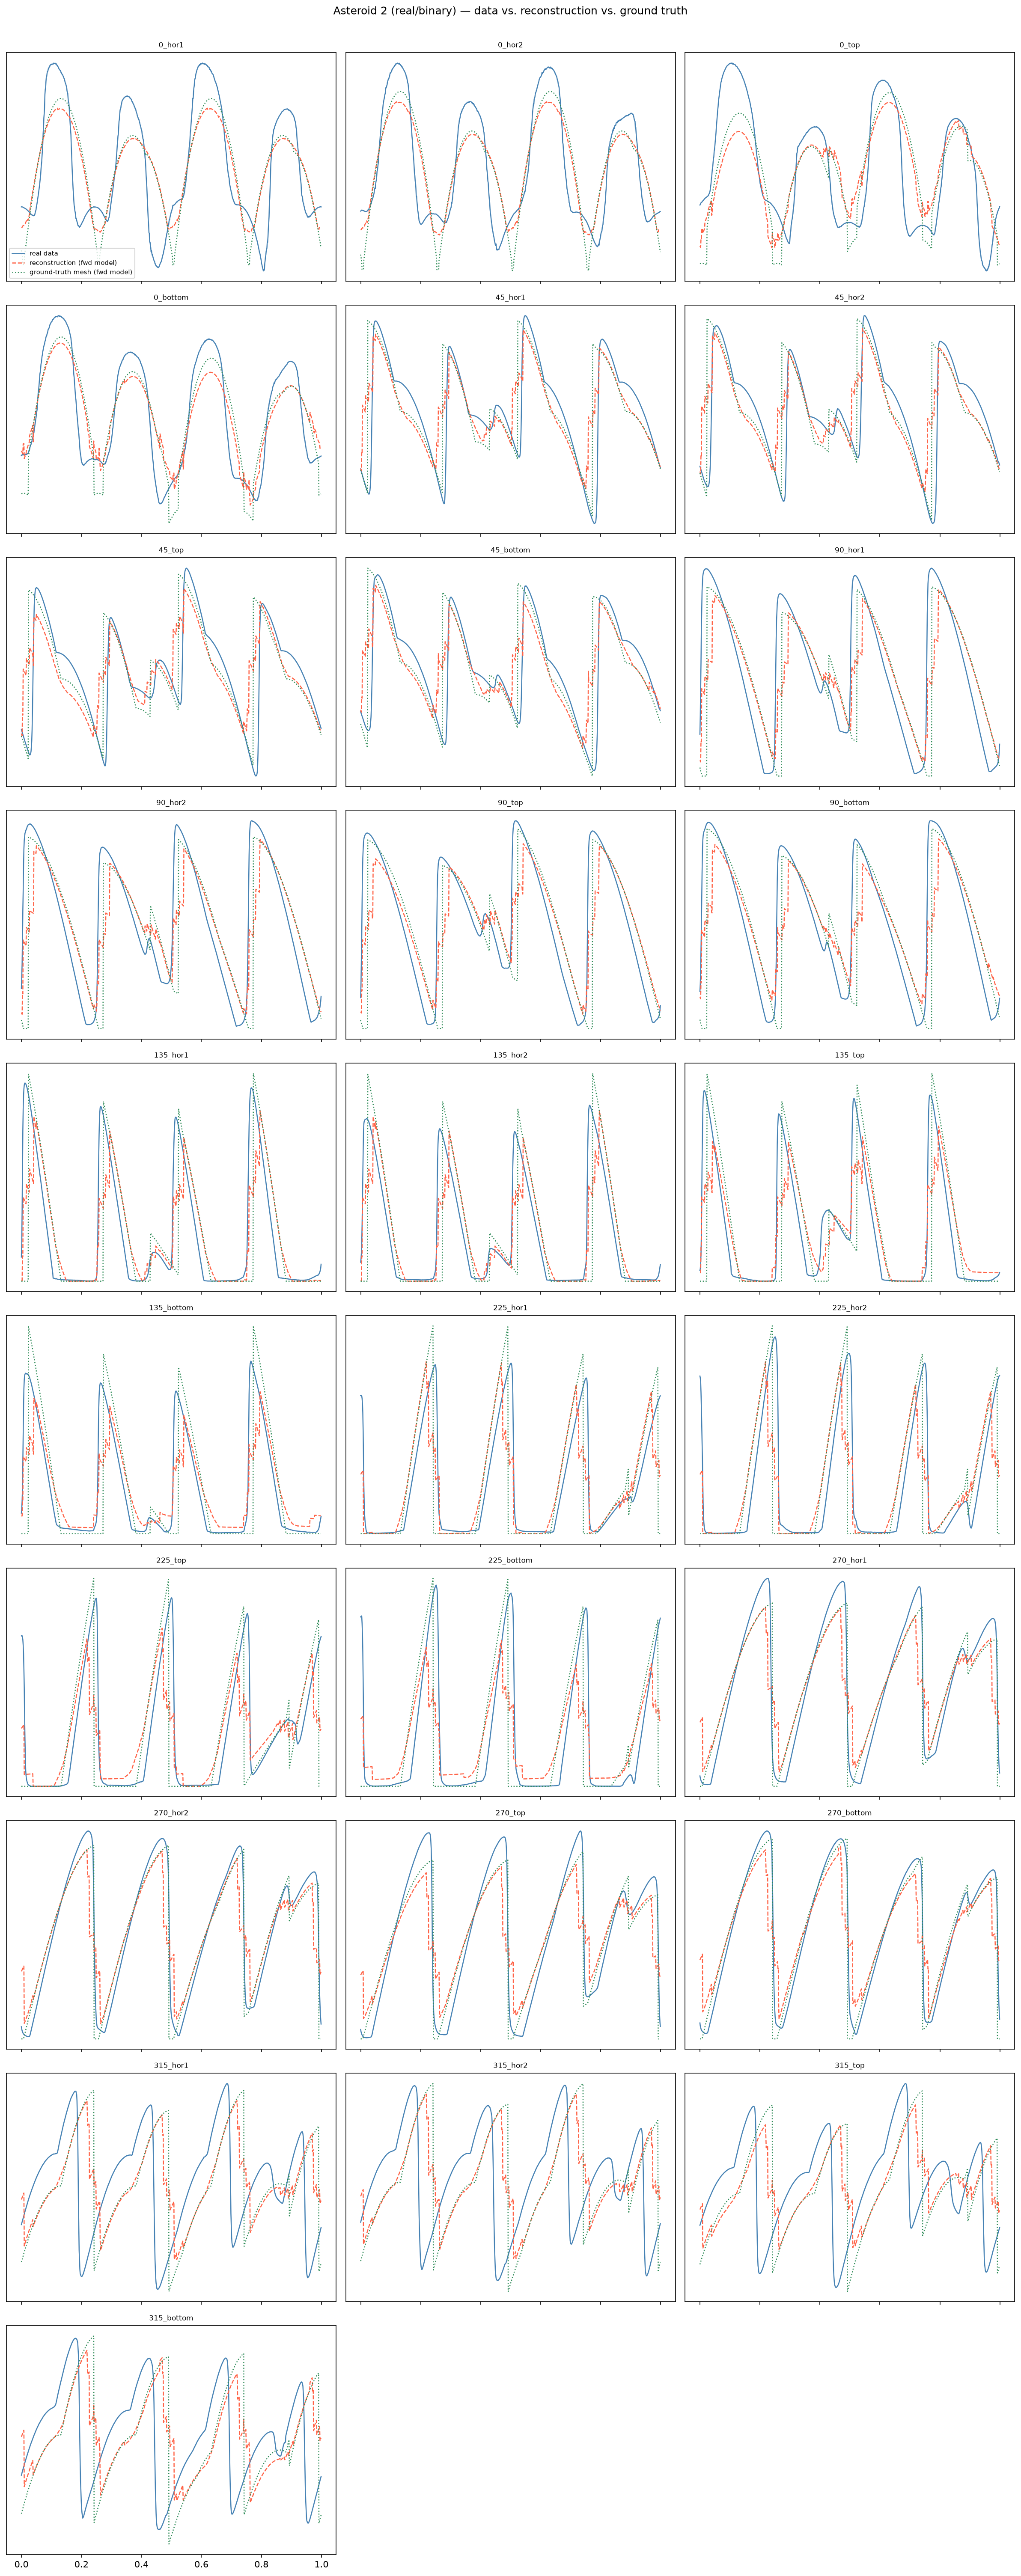

In [13]:
display(Image(filename=str(paths["lightcurves_png"])))